# 01 – Data Exploration: AI4Mars (Curiosity Navcam)

Exploring the AI4Mars dataset before building the segmentation model:
folder structure, file pairing, image sizes, label values, class balance and camera types.

**Data:** AI4Mars merged v0.6 (NASA JPL, CC BY 4.0), `msl/ncam` subset.

**Goal:** understand the data well enough to make the decisions listed at the end.

Each section follows the same pattern: **question → code → findings**.

## Setup

In [1]:
from pathlib import Path
import numpy as np 
from PIL import Image
import matplotlib.pyplot as plt 

DATA_DIR = Path(r"C:\data-mars\msl\ncam")
IMG_DIR = DATA_DIR / "images" / "edr"
ROVER_DIR = DATA_DIR / "images" / "mxy"
RANGE_DIR = DATA_DIR / "images" / "rng-30m"
TRAIN_LBL_DIR = DATA_DIR / "labels" / "train"
TEST_LBL_DIR = DATA_DIR / "labels" / "test" / "masked-gold-min3-100agree"

for d in [IMG_DIR, ROVER_DIR, RANGE_DIR, TRAIN_LBL_DIR, TEST_LBL_DIR]:
    print(d.name, d.exists())

edr True
mxy True
rng-30m True
train True
masked-gold-min3-100agree True


## Dataset notes (from `info.md` and `label_keys.json`)

- **Classes (NAV key):** `0` soil, `1` bedrock, `2` sand, `3` big rock, `255` no label.
- **Train labels:** crowdsourced. A pixel keeps its label only if at least 3 people labelled it and 2/3 of them agreed; otherwise it is set to 255.
- **Test labels:** expert labels with 100% agreement, in three versions (`min1`, `min2`, `min3`), depending on how many experts had to label a pixel. `min3` is the sparsest and strictest.
- **Masking:** the rover and areas further than 30 m are already set to 255 in the labels.
- **Mask files:** `MXY` = rover mask (1 = rover); `RNG-30M` = range mask (1 = further than 30 m). Both are binary images.
- **Known issues (`TODO.md`):** some labels are empty, and some images have no label.
- **Citation:** Swan et al., *AI4MARS: A Dataset for Terrain-Aware Autonomous Driving on Mars*, CVPR Workshops 2021.

## 1. **Folder structure and file pairing** 

*Where are the images, labels and masks, and how are their files paired?*

In [2]:
# Explore the file names in each folder

# produces them one by one as a generator, and sorted(...) collects them into a sorted list of Path objects
all_imgs = sorted(IMG_DIR.glob("*.JPG"))  # gives a list of all image file paths 
# images are .JPG; labels and masks are .png
print(len(all_imgs))

# tuples: a folder, and the pattern to search it with
folders = [
    (IMG_DIR, "*.JPG"),
    (ROVER_DIR, "*.png"),
    (RANGE_DIR, "*.png"),
    (TRAIN_LBL_DIR, "*.png"),
    (TEST_LBL_DIR, "*.png"),
]

for d, pattern in folders:
    files = sorted(d.glob(pattern))
    print(d.name, len(files))
    for p in files[:3]: # p is one Path at a time, first 3 files, and p.name is its filename
        print("   ", p.name)

18127
edr 18127
    NLA_397586928EDR_F0010008AUT_04096M1.JPG
    NLA_397586934EDR_F0010008AUT_04096M1.JPG
    NLA_397681339EDR_F0020000AUT_04096M1.JPG
mxy 18097
    NLA_397586928MXY_F0010008AUT_04096M1.png
    NLA_397586934MXY_F0010008AUT_04096M1.png
    NLA_397681339MXY_F0020000AUT_04096M1.png
rng-30m 18096
    NLA_397586928RNG_F0010008AUT_04096M1.png
    NLA_397586934RNG_F0010008AUT_04096M1.png
    NLA_397681339RNG_F0020000AUT_04096M1.png
train 16064
    NLA_397586934EDR_F0010008AUT_04096M1.png
    NLA_397681339EDR_F0020000AUT_04096M1.png
    NLA_397681372EDR_F0020000AUT_04096M1.png
masked-gold-min3-100agree 322
    NLA_409036068EDR_F0051606NCAM00348M1_merged.png
    NLA_409036116EDR_F0051606NCAM00348M1_merged.png
    NLA_409036860EDR_F0051662NCAM00346M1_merged.png


**The naming pattern, the key to matching files:**

| File | Example name |
|---|---|
| Image (`edr`) | `NLA_397586934EDR_F0010008AUT_04096M1.JPG` |
| Train label | `NLA_397586934EDR_F0010008AUT_04096M1.png` |
| Test label | `NLA_409036068EDR_F0051606NCAM00348M1_merged.png` |
| Rover mask | `NLA_397586934MXY_F0010008AUT_04096M1.png` |
| Range mask | `NLA_397586934RNG_F0010008AUT_04096M1.png` |

So:
- Train label ↔ image: identical stem, only the extension differs.
- Test label ↔ image: same, but remove _merged first.
- Masks ↔ image: replace MXY or RNG with EDR.

(NLA = Navcam, left camera, and the long number is the spacecraft clock time when the photo was taken.)

In [3]:
img_stems = set()
for img in all_imgs:
    img_stems.add(img.stem)

train_stems = set()
for lbl in sorted(TRAIN_LBL_DIR.glob("*.png")):
    train_stems.add(lbl.stem)

test_stems = set() 
for lbl in sorted(TEST_LBL_DIR.glob("*.png")):
    test_stems.add(lbl.stem.replace("_merged", ""))

train_lbl_with_img = train_stems & img_stems
test_lbl_with_img = test_stems & img_stems
train_test_overlap = train_stems & test_stems #must be empty!
img_with_no_lbl = img_stems - train_stems - test_stems

print(len(train_lbl_with_img), "train labels with an image")
print(len(test_lbl_with_img), "test labels with an image")
print(len(train_test_overlap), "train/test overlap")
print(len(img_with_no_lbl), "images with no label")


16064 train labels with an image
322 test labels with an image
0 train/test overlap
1741 images with no label


**Findings**
- 18,127 Navcam images, 16,064 train labels and 322 test (`min3`) labels. These counts match the AI4Mars paper.
- Every train and test label has a matching image.
- No image appears in both train and test (overlap = 0), so there is no test leakage.
- 1,741 images have no label at all; they are not used.
- A few images have no rover mask (18,097 masks) or range mask (18,096 masks). This only matters for evaluation and visualisations.

## 2. Image sizes

*What resolution and colour mode do the images and labels have? Are they all the same?*

In [4]:
import random 
from collections import Counter # works like a dictionary that counts things

random.seed(0) # same random picks every run, reproducible 

all_imgs = sorted(IMG_DIR.glob("*.JPG")) 
train_lbls = sorted(TRAIN_LBL_DIR.glob("*.png"))
sample = random.sample(all_imgs, 50)
sample_train = random.sample(train_lbls, 50)

sizes = Counter()
modes = Counter()

for p in sample:
    with Image.open(p) as img: 
        sizes[img.size] += 1
        modes[img.mode] += 1

print(sizes)
print(modes)

sizes_lbl = Counter()
modes_lbl = Counter() 

for s in sample_train:
    with Image.open(s) as lbl:
        sizes_lbl[lbl.size] += 1
        modes_lbl[lbl.mode] += 1

print(sizes_lbl)
print(modes_lbl)

Counter({(1024, 1024): 50})
Counter({'L': 50})
Counter({(1024, 1024): 50})
Counter({'L': 50})


**Findings** (random samples of 50 images and 50 train labels)
- All images and labels are 1024×1024, greyscale (L).
- Model input = 1 channel. Resize to 512×512 for training. Use nearest-neighbour interpolation for labels.

## 3. Label values

*Which pixel values appear in the labels, how much is unlabelled, and are any labels empty?*

In [5]:
# looking at actual pixel values 

train_lbls = sorted(TRAIN_LBL_DIR.glob("*.png"))
sample_train = random.sample(train_lbls, 50)
test_lbls = sorted(TEST_LBL_DIR.glob("*.png"))
sample_test = random.sample(test_lbls, 50)

for p in sample_train[:5]:
    with Image.open(p) as lbl:
        arr = np.array(lbl) # a 1024x1024 grid of numbers 
        print(p.name, np.unique(arr, return_counts=True))

for p in sample_test[:5]:
    with Image.open(p) as lbl:
        arr = np.array(lbl) 
        print(p.name, np.unique(arr, return_counts=True))

all_values = set()
empty = 0

for p in sample_train:
    with Image.open(p) as lbl:
        arr = np.array(lbl) 
        all_values.update(np.unique(arr).tolist())
        if (arr == 255).all():
            empty += 1

print("values seen:", sorted(all_values))
print("empty labels:", empty, "of", len(sample_train))

# reset for test loop 
all_values = set()
empty = 0

for p in sample_test:
    with Image.open(p) as lbl:
        arr = np.array(lbl) 
        all_values.update(np.unique(arr).tolist())
        if (arr == 255).all():
            empty += 1

print("values seen:", sorted(all_values))
print("empty labels:", empty, "of", len(sample_test))


NLB_432125263EDR_F0160000NCAM00297M1.png (array([  0, 255], dtype=uint8), array([389471, 659105]))
NLB_611270644EDR_F0751564NCAM00354M1.png (array([  0,   2, 255], dtype=uint8), array([201895, 476062, 370619]))
NLA_408770884EDR_F0051530NCAM00347M1.png (array([  1, 255], dtype=uint8), array([1013068,   35508]))
NLB_574253238EDR_F0681816NCAM00258M1.png (array([  0, 255], dtype=uint8), array([ 74701, 973875]))
NLA_602484522EDR_F0732514NCAM00203M1.png (array([  0,   1,   2, 255], dtype=uint8), array([543325,  55519,   6381, 443351]))
NLB_493996945EDR_F0491876NCAM00353M1_merged.png (array([  1,   2, 255], dtype=uint8), array([233387,  70189, 745000]))
NLB_443663326EDR_F0251238NCAM00289M1_merged.png (array([  0, 255], dtype=uint8), array([654268, 394308]))
NLB_463099226EDR_F0410712NCAM00385M1_merged.png (array([  1, 255], dtype=uint8), array([485158, 563418]))
NLB_525149600EDR_F0570774NCAM07753M1_merged.png (array([255], dtype=uint8), array([1048576]))
NLB_455642442EDR_F0340774NCAM00252M1_me

**Findings** (random samples of 50 train and 50 test labels)
1. **Only the expected values appear:** 0, 1, 2, 3 and 255.
2. **Each label contains only a few classes.** Most labels have 1–3 of the 4 classes (e.g. only soil, or bedrock + sand), so the model learns from many images that each show a small part of the terrain types.
3. **Many pixels are unlabelled (255):**
   - Train: roughly 20–80% unlabelled (e.g. 212,097 of 1,048,576 pixels ≈ 20%).
   - Test (`min3`): much sparser, often 85–98% unlabelled. One test label has only about 26,500 labelled pixels (≈ 2.5%).
   - → Ignoring 255 in the loss is essential (Decision 6).
4. **Big rock (3) is rare.** It appears in only one of the 10 printed labels (about 14,000 pixels, ≈ 1.3% of that image) and not at all in the test sample.
5. **Some labels are completely empty:**
   - Train: 1 of 50 (≈ 2%), so roughly 300 of the 16,064.
   - Test: 5 of 50 (10%).

## 4. Visualisation

*Image, label and overlay for 5 random training examples. Do the labels look right?*

Colours: soil = brown, bedrock = grey, sand = yellow, big rock = red. Unlabelled pixels are left uncoloured.

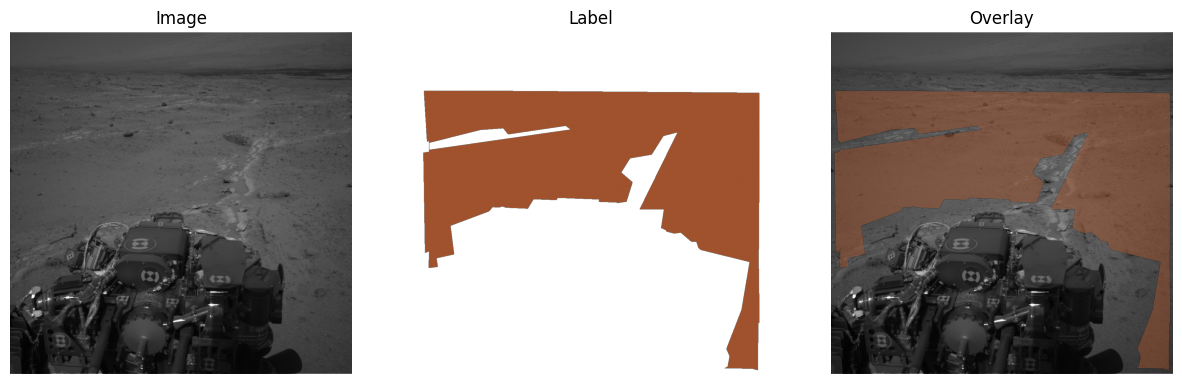

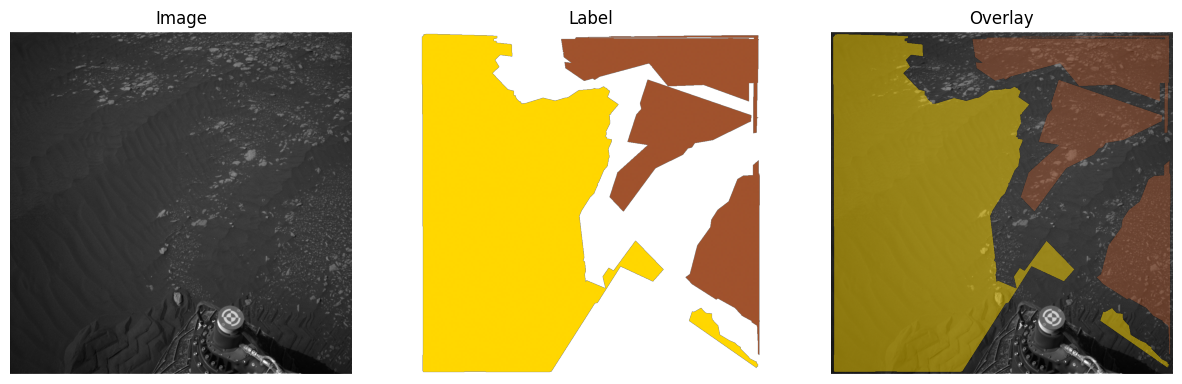

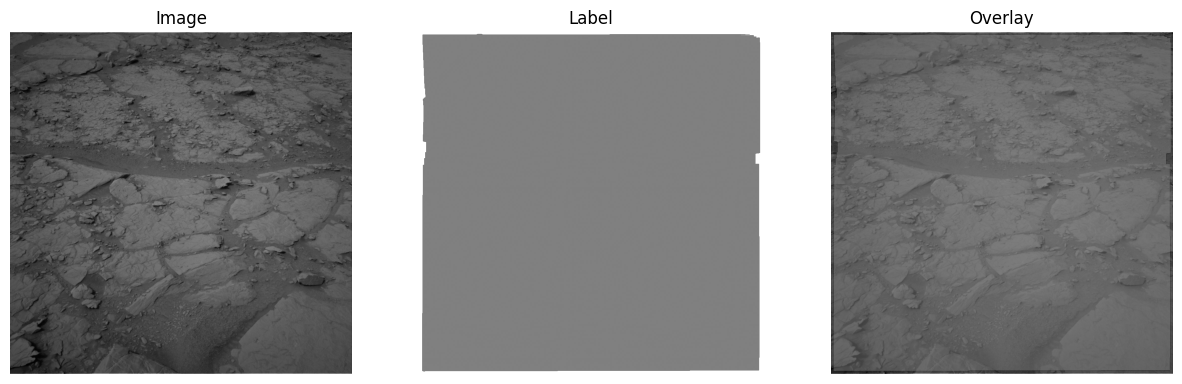

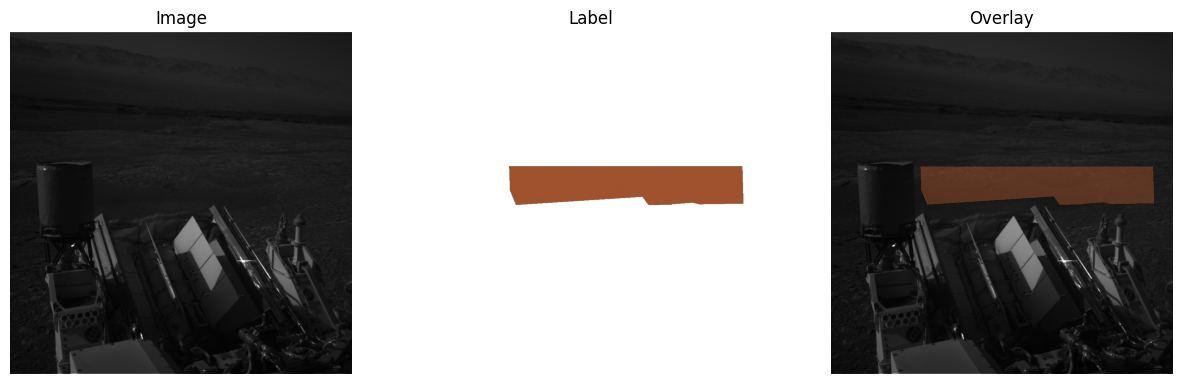

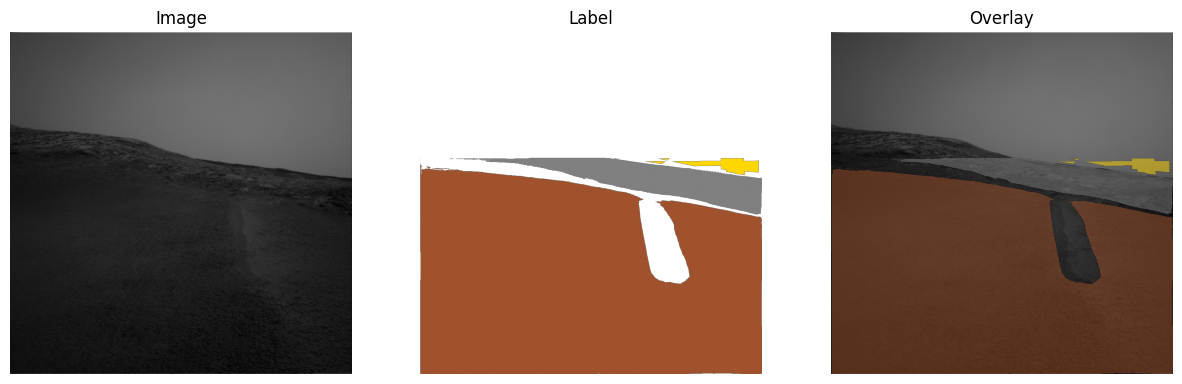

In [6]:
# three panels per example, photo | label | photo with label on top
from matplotlib.colors import ListedColormap

cmap = ListedColormap(["sienna", "gray", "gold", "red"]) # soil, bedrock, sand, big rock

for lbl in sample_train[:5]:
    img_path = IMG_DIR / (lbl.stem + ".JPG")

    with Image.open(img_path) as im:
        img_arr = np.array(im)

    with Image.open(lbl) as lb:
        lbl_arr = np.array(lb)

    masked = np.ma.masked_equal(lbl_arr, 255) # hides unlabelled pixels, the 255s

    fig, axes = plt.subplots(1, 3, figsize=(15, 5)) # a new figure per example 

    axes[0].imshow(img_arr, cmap="gray")
    axes[0].set_title("Image")

    axes[1].imshow(masked, cmap=cmap, vmin=0, vmax=3)
    axes[1].set_title("Label")

    axes[2].imshow(img_arr, cmap="gray") # image underneath
    axes[2].imshow(masked, cmap=cmap, vmin=0, vmax=3, alpha=0.5) # label on top
    axes[2].set_title("Overlay")

    for ax in axes:
        ax.axis("off") # hide the axis ticks
    plt.show()

**Findings**
1. **Labels are rough polygons, not precise outlines.** Crowdsourced labellers drew shapes with straight edges, so boundaries do not follow the real edges of rocks or sand (in example 1, the sand polygon covers parts of rocks). Even a perfect model cannot score 100%, and predictions near boundaries will look "wrong" against these labels.
2. **The rover is correctly left unlabelled.** In examples 2–5, the wheels and rover body have no colour, as the documentation describes.
3. **Distant areas are unlabelled too.** In example 4, the band near the horizon has no label: the >30 m range mask at work.
4. **Big rock is under-labelled.** In example 1, many rocks are visible but only one is labelled big rock; in example 2, rocks are labelled as bedrock. So big rock is not only rare but also inconsistently labelled. A model that correctly predicts unlabelled rocks will be counted as wrong.
5. **Large unlabelled gaps.** Labellers often skipped areas between regions (the gaps), consistent with the 20–80% unlabelled pixels measured in Section 3.
6. **Brightness varies a lot.** Some images are very dark, which motivates normalisation and brightness augmentation.

## 5. Class balance

*What share of labelled pixels does each class have, and how many images contain each class? Train: random sample of 500. Test: all 322 `min3` labels.*

pixel share %: [37.69 51.08 10.48  0.75]
images containing class: [253 325 157  72] of 500


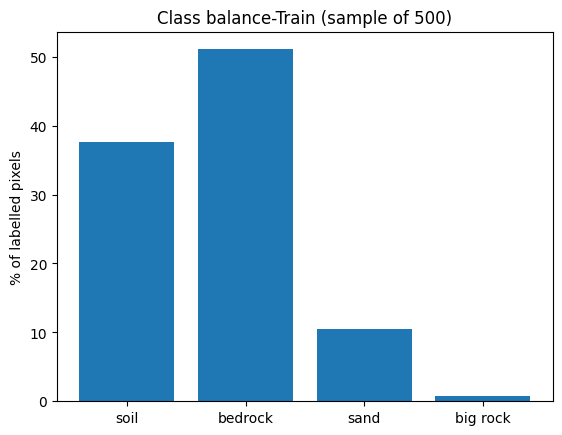

pixel share %: [51.35 22.39 26.19  0.07]
images containing class: [150 142 110   5] of 322


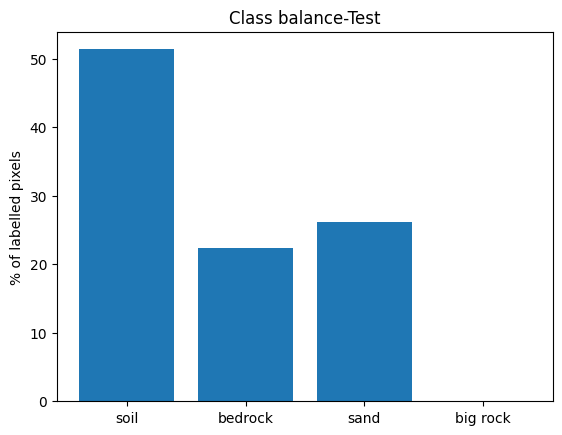

In [7]:
# measuring how rare each class is 

random.seed(0)
sample_500 = random.sample(train_lbls, 500)
totals = np.zeros(4, dtype=np.int64) # an array of four zeros, pixels per class
present = np.zeros(4, dtype=np.int64)  # images containing each class

for p in sample_500: # count the pixels per class, ignoring 255
    with Image.open(p) as lb:
        arr = np.array(lb)
    counts = np.bincount(arr[arr != 255], minlength=4)  
    totals += counts 
    present += counts > 0

percent = totals / totals.sum() * 100
classes = ["soil", "bedrock", "sand", "big rock"]

print("pixel share %:", percent.round(2))
print("images containing class:", present, "of", len(sample_500))

plt.bar(classes, percent)
plt.ylabel("% of labelled pixels")
plt.title("Class balance-Train (sample of 500)")
plt.show()

# now, for the test set 

totals_test = np.zeros(4, dtype=np.int64)  
present_test = np.zeros(4, dtype=np.int64)  

for p in test_lbls: 
    with Image.open(p) as lb:
        arr = np.array(lb)
    counts = np.bincount(arr[arr != 255], minlength=4)  
    totals_test += counts 
    present_test += counts > 0

percent_test = totals_test / totals_test.sum() * 100
classes = ["soil", "bedrock", "sand", "big rock"]

print("pixel share %:", percent_test.round(2))
print("images containing class:", present_test, "of", len(test_lbls))

plt.bar(classes, percent_test)
plt.ylabel("% of labelled pixels")
plt.title("Class balance-Test")
plt.show()

**Findings**

| | Soil | Bedrock | Sand | Big rock |
|---|---|---|---|---|
| Train, pixel share (sample of 500) | 37.7% | 51.1% | 10.5% | 0.75% |
| Train, images containing class | 253 | 325 | 157 | 72 |
| Test (`min3`), pixel share | 51.4% | 22.4% | 26.2% | 0.07% |
| Test (`min3`), images containing class | 150 | 142 | 110 | 5 |

1. **Strong class imbalance.** Big rock is about 70 times rarer than bedrock. It appears in 14% of train images, but always as tiny areas (0.75% of pixels). A model that never predicts big rock would lose less than 1% of pixel accuracy, so overall accuracy would look high while one class fails completely.
   - → Per-class IoU and mean IoU are the main metrics, not pixel accuracy (Decision 12). This is also why the paper's 96% overall accuracy says little on its own.
   - → Natural experiment: imbalance-aware losses (weighted cross-entropy, Dice, focal) vs plain cross-entropy (Decision 15).
2. **Big rock cannot be measured reliably on `min3`.** With 5 images and 0.07% of pixels, any big-rock score on `min3` is essentially noise (Decision 13).
3. **Train and test have different distributions.** Train is mostly bedrock; test is mostly soil, with 2.5 times more sand. This distribution shift means validation results (from train) will not perfectly predict test results (Decision 14).

## 6. Camera types

*How many Mastcam (`mcam`) images are there, and are they really colour?*

In [8]:
# two facts about the Mastcam images, how many there are and whether they’re really colour

MCAM_DIR = Path(r"C:\data-mars\msl\mcam")
print([p.name for p in MCAM_DIR.iterdir()]) # lists everything directly inside a folder 

mcam_imgs = sorted(MCAM_DIR.rglob("*.JPG"))
print(len(mcam_imgs))

mcam_labels = sorted(MCAM_DIR.rglob("*.png"))
print(len(mcam_labels))

for img in mcam_imgs[:5]:
    with Image.open(img) as im:
        print(im.mode) # should see "RGB" (colour), not "L" (greyscale)

['images', 'labels']
9099
9099
RGB
RGB
RGB
RGB
RGB


**Findings**
- **ncam (Navcam):** greyscale (mode `L`) stereo images that the rover uses to drive. 18,127 images (16,064 train labels, 322 test labels). Rover and range masks exist.
- **mcam (Mastcam):** colour (mode `RGB`) images for science and human operators. 9,099 images and 9,099 label files. No rover or range masks exist for Mastcam (`info.md`).
- → Train on ncam; Mastcam is a later transfer experiment (Decisions 1–2).

## Decisions
1. **Camera:** train on ncam (Navcam) only: the driving camera, has rover/range masks, greyscale.
2. **Later experiment:** test transfer to mcam (Mastcam, colour).
3. **Input:** 1 channel (all images are 1024×1024 greyscale, mode L).
4. **Resolution:** resize images and labels to 512×512 for training (faster, less memory). Labels use nearest-neighbour interpolation so no fake class values appear.
5. **Classes:** 4 classes: 0 soil, 1 bedrock, 2 sand, 3 big rock.
6. **Unlabelled pixels:** value 255 is ignored in the loss (`ignore_index=255`) and in all metrics.
7. **Empty labels:** skip labels that contain only 255 (about 2% of train, about 10% of test in a sample of 50).
8. **Unlabelled images:** the 1,741 images without any label are not used.
9. **Splits:** train = `labels/train` (16,064); validation = a random part of train (e.g. 10%); test = expert labels, untouched until final evaluation.
10. **Main evaluation:** test set `min3` (322 labels, strictest expert agreement). Optionally also report `min1`/`min2`, since min3 is very sparse and may contain very few big-rock pixels.
11. **Masks:** the rover (MXY) and range (RNG-30M) masks are already applied in the labels; use them to hide predictions in those regions in evaluation and visualisations.
12. **Main metric:** per-class IoU and mean IoU (not pixel accuracy, which is misleading because of class imbalance).
13. **Big rock:** too rare in min3 (0.07%, 5 images) to evaluate reliably → also report on min1 (check its counts); flag big-rock results as low-confidence.
14. **Distribution shift:** train is bedrock-heavy, test is soil/sand-heavy → expect a validation/test gap; discuss in README.
15. **Planned experiment:** imbalance-aware losses (weighted CE, Dice, focal) vs plain CE, judged by big-rock and sand IoU.

## To check
- Run the class-balance code on `min1`: does it contain enough big-rock pixels to evaluate that class?
- Exact class percentages over the full train set (the numbers above come from a sample of 500).